In [1]:
import numpy as np
import pandas as pd
from tqdm import tqdm
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score, roc_curve
import statsmodels.api as sm

import pickle

import xgboost as xgb
print(xgb.__version__)

3.2.0


In [71]:
train = pd.read_csv('../Data/train_features_imputed.csv')
oot1 = pd.read_csv('../Data/oot1_features_imputed.csv')
oot2 = pd.read_csv('../Data/oot2_features_imputed.csv')

all_features = pickle.load(open('../Files/all_features.pkl', 'rb'))
identifier_cols = all_features['identifier_features']
features_to_select = pickle.load(open('../Files/selected_features_before_vif.csv', 'rb'))['final_selected_features_before_vif']

In [72]:
identifier_cols

['id', 'stmt_date', 'data_type', 'default', 'ateco_sector']

In [73]:
vif = pd.read_csv('../Files/VIF.csv').sort_values(by='VIF', ascending=False)
features_to_select = vif.query('feature != "const"')['feature'].tolist()
vif_feats = list(vif.query('VIF <= 5')['feature'])
vif_feats

['st_debt_share',
 'equity_to_assets',
 'operating_loss_flag',
 'nonpositive_ebitda_flag',
 'receivables_to_assets',
 'account_payables_to_assets',
 'net_loss_flag',
 'operating_cashflow_to_liabilities',
 'cash_to_debt_st',
 'current_assets_to_debt_st',
 'net_profit_to_assets',
 'operating_cashflow_to_assets',
 'cash_flow_to_debt',
 'cash_to_assets',
 'negative_equity_flag',
 'ebitda_to_assets',
 'interest_coverage_proxy',
 'operating_margin',
 'debt_to_ebitda',
 'const']

In [74]:
final_model_feats = [c for c in features_to_select if c in vif_feats]
len(final_model_feats), len(features_to_select), len(vif_feats)

(19, 22, 20)

In [102]:
final_model_feats

['st_debt_share',
 'equity_to_assets',
 'operating_loss_flag',
 'nonpositive_ebitda_flag',
 'receivables_to_assets',
 'account_payables_to_assets',
 'net_loss_flag',
 'operating_cashflow_to_liabilities',
 'cash_to_debt_st',
 'current_assets_to_debt_st',
 'net_profit_to_assets',
 'operating_cashflow_to_assets',
 'cash_flow_to_debt',
 'cash_to_assets',
 'negative_equity_flag',
 'ebitda_to_assets',
 'interest_coverage_proxy',
 'operating_margin',
 'debt_to_ebitda']

In [75]:
train = train[identifier_cols + final_model_feats]
oot1 = oot1[identifier_cols + final_model_feats]
oot2 = oot2[identifier_cols + final_model_feats]

In [76]:
X = train.copy()
y = pd.Series(np.asarray(train['default']), index=X.index)

print('Base rate:', y.mean())

flag_cols = [c for c in features_to_select if 'flag' in c]

rows = []

for col in flag_cols:
    table = pd.crosstab(X[col], y).reindex(
        index=[0, 1],
        columns=[0, 1],
        fill_value=0
    )

    rows.append({
        "feature": col,
        "n_flagged": table.loc[1].sum(),
        "defaults_flagged": table.loc[1, 1],
        "nondefaults_flagged": table.loc[1, 0],
        "default_rate_flagged": (
            table.loc[1, 1] / table.loc[1].sum()
            if table.loc[1].sum() > 0 else np.nan
        ),
        "zero_cell": (table == 0).any().any()
    })

flag_summary = pd.DataFrame(rows)

display(flag_summary.sort_values(
    ["zero_cell", "n_flagged"],
    ascending=[False, True]
))

Base rate: 0.013988544118606026


,feature,n_flagged,defaults_flagged,nondefaults_flagged,default_rate_flagged,zero_cell
3,negative_equity_flag,17744,1631,16113,0.091918,False
1,nonpositive_ebitda_flag,73229,2962,70267,0.040448,False
0,operating_loss_flag,104076,3447,100629,0.033120,False
2,net_loss_flag,164335,4329,160006,0.026343,False


In [77]:
def get_scores(df, features, model, ID_cols):
    df_sm = sm.add_constant(df[features].astype(float), has_constant='add')
    df_sm = df_sm[model.model.exog_names]
    pred = model.predict(df_sm)
    
    return pd.concat([df[ID_cols], pd.DataFrame({'y_true': df['default'], 'y_pred': pred})], axis=1)

In [78]:
X = sm.add_constant(train[final_model_feats].astype(float), has_constant='add')
y = np.asarray(train['default'], dtype=float)

result = sm.Logit(y, X).fit(maxiter=5000)
print(result.get_margeff().summary())

Optimization terminated successfully.
         Current function value: 0.064684
         Iterations 12
        Logit Marginal Effects       
Dep. Variable:                      y
Method:                          dydx
At:                           overall
                                       dy/dx    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------------------------
st_debt_share                         0.0095      0.001     13.995      0.000       0.008       0.011
equity_to_assets                     -0.0032      0.000     -6.650      0.000      -0.004      -0.002
operating_loss_flag                   0.0021      0.001      3.077      0.002       0.001       0.003
nonpositive_ebitda_flag               0.0085      0.001     12.739      0.000       0.007       0.010
receivables_to_assets                 0.0140      0.001     20.636      0.000       0.013       0.015
account_payables_to_assets     

In [79]:
scores_train_1 = get_scores(train, final_model_feats, result, identifier_cols)
scores_oot1_1 = get_scores(oot1, final_model_feats, result, identifier_cols)
scores_oot2_1 = get_scores(oot2, final_model_feats, result, identifier_cols)

print(f'Train AUC: {roc_auc_score(scores_train_1["y_true"], scores_train_1["y_pred"]):.4f}')
print(f'OOT1 AUC: {roc_auc_score(scores_oot1_1["y_true"], scores_oot1_1["y_pred"]):.4f}')
print(f'OOT2 AUC: {roc_auc_score(scores_oot2_1["y_true"], scores_oot2_1["y_pred"]):.4f}')

/opt/homebrew/Caskroom/miniconda/base/envs/nlp/lib/python3.10/site-packages/statsmodels/discrete/discrete_model.py:2620: RuntimeWarning: overflow encountered in exp
  return 1 / (1 + np.exp(-X))


Train AUC: 0.7611
OOT1 AUC: 0.7535
OOT2 AUC: 0.7777


In [80]:
result.params[result.pvalues > 0.05]

operating_cashflow_to_liabilities    4.918005e-04
cash_to_debt_st                      1.748639e-04
current_assets_to_debt_st           -1.784332e-04
operating_cashflow_to_assets        -1.392097e-01
cash_flow_to_debt                    7.952788e-06
ebitda_to_assets                     1.757719e-02
interest_coverage_proxy              3.908725e-07
debt_to_ebitda                      -3.136394e-06
dtype: float64

In [81]:
drop_features = [
    'operating_cashflow_to_liabilities', 'cash_to_debt_st', 'current_assets_to_debt_st', 'operating_cashflow_to_assets',
    'cash_flow_to_debt', 'ebitda_to_assets', 'interest_coverage_proxy', 'debt_to_ebitda'
]

In [82]:
updated_feats = list(set(final_model_feats) - set(drop_features))
X = sm.add_constant(train[updated_feats].astype(float), has_constant='add')
y = np.asarray(train['default'], dtype=float)

result_2 = sm.Logit(y, X).fit(maxiter=5000)
print(result_2.get_margeff().summary())

Optimization terminated successfully.
         Current function value: 0.064698
         Iterations 9
        Logit Marginal Effects       
Dep. Variable:                      y
Method:                          dydx
At:                           overall
                                dy/dx    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------------------
net_loss_flag                  0.0089      0.000     18.782      0.000       0.008       0.010
account_payables_to_assets     0.0069      0.001      8.550      0.000       0.005       0.008
st_debt_share                  0.0097      0.001     14.314      0.000       0.008       0.011
receivables_to_assets          0.0139      0.001     20.556      0.000       0.013       0.015
nonpositive_ebitda_flag        0.0086      0.001     12.877      0.000       0.007       0.010
operating_margin            5.343e-08   1.76e-08      3.037      0.002    1.89e-0

In [83]:
scores_train_2 = get_scores(train, updated_feats, result_2, identifier_cols)
scores_oot1_2 = get_scores(oot1, updated_feats, result_2, identifier_cols)
scores_oot2_2 = get_scores(oot2, updated_feats, result_2, identifier_cols)

print(f'Train AUC: {roc_auc_score(scores_train_2["y_true"], scores_train_2["y_pred"]):.4f}')
print(f'OOT1 AUC: {roc_auc_score(scores_oot1_2["y_true"], scores_oot1_2["y_pred"]):.4f}')
print(f'OOT2 AUC: {roc_auc_score(scores_oot2_2["y_true"], scores_oot2_2["y_pred"]):.4f}')

Train AUC: 0.7608
OOT1 AUC: 0.7535
OOT2 AUC: 0.7776


In [104]:
updated_feats

['net_loss_flag',
 'account_payables_to_assets',
 'st_debt_share',
 'receivables_to_assets',
 'nonpositive_ebitda_flag',
 'operating_margin',
 'operating_loss_flag',
 'negative_equity_flag',
 'cash_to_assets',
 'equity_to_assets',
 'net_profit_to_assets']

In [85]:
train['operating_margin'].describe()

count    4.753890e+05
mean    -1.728943e+02
std      2.217379e+04
min     -9.022660e+06
25%      1.259376e-02
50%      4.554043e-02
75%      1.152991e-01
max      1.063029e+06
Name: operating_margin, dtype: float64

In [86]:
updated_feats_2 = list(set(final_model_feats) - set(drop_features) - set(['operating_margin']))
X = sm.add_constant(train[updated_feats_2].astype(float), has_constant='add')
y = np.asarray(train['default'], dtype=float)

result_3 = sm.Logit(y, X).fit(maxiter=5000)
print(result_3.get_margeff().summary())

Optimization terminated successfully.
         Current function value: 0.064707
         Iterations 9
        Logit Marginal Effects       
Dep. Variable:                      y
Method:                          dydx
At:                           overall
                                dy/dx    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------------------
net_loss_flag                  0.0089      0.000     18.812      0.000       0.008       0.010
account_payables_to_assets     0.0068      0.001      8.512      0.000       0.005       0.008
st_debt_share                  0.0097      0.001     14.310      0.000       0.008       0.011
receivables_to_assets          0.0140      0.001     20.595      0.000       0.013       0.015
nonpositive_ebitda_flag        0.0085      0.001     12.836      0.000       0.007       0.010
operating_loss_flag            0.0021      0.001      2.976      0.003       0.00

In [87]:
scores_train_3 = get_scores(train, updated_feats, result_2, identifier_cols)
scores_oot1_3 = get_scores(oot1, updated_feats, result_2, identifier_cols)
scores_oot2_3 = get_scores(oot2, updated_feats, result_2, identifier_cols)

print(f'Train AUC: {roc_auc_score(scores_train_3["y_true"], scores_train_3["y_pred"]):.4f}')
print(f'OOT1 AUC: {roc_auc_score(scores_oot1_3["y_true"], scores_oot1_3["y_pred"]):.4f}')
print(f'OOT2 AUC: {roc_auc_score(scores_oot2_3["y_true"], scores_oot2_3["y_pred"]):.4f}')

Train AUC: 0.7608
OOT1 AUC: 0.7535
OOT2 AUC: 0.7776


In [103]:
updated_feats_2

['net_loss_flag',
 'account_payables_to_assets',
 'st_debt_share',
 'receivables_to_assets',
 'nonpositive_ebitda_flag',
 'operating_loss_flag',
 'negative_equity_flag',
 'cash_to_assets',
 'equity_to_assets',
 'net_profit_to_assets']

In [88]:
ci = result_3.conf_int(alpha=0.05)

summary = pd.DataFrame({
    'beta': result_3.params,
    'std_error': result_3.bse,
    'p_value': result_3.pvalues,
    'ci_lower': ci[0],
    'ci_upper': ci[1]
})
summary.to_csv('../Artifacts/logit_model_summary.csv')
display(summary.sort_values(by='p_value', ascending=False))

,beta,std_error,p_value,ci_lower,ci_upper
operating_loss_flag,0.157377,0.052855,2.906086e-03,0.053782,0.260971
equity_to_assets,-0.240617,0.036730,5.714163e-11,-0.312605,-0.168628
cash_to_assets,-1.206110,0.157165,1.664729e-14,-1.514147,-0.898073
account_payables_to_assets,0.523757,0.061327,1.337233e-17,0.403559,0.643955
nonpositive_ebitda_flag,0.654729,0.050527,2.117909e-38,0.555697,0.753760
st_debt_share,0.742117,0.051227,1.469227e-47,0.641714,0.842521
net_loss_flag,0.680969,0.035300,6.387735e-83,0.611783,0.750155
net_profit_to_assets,-1.389334,0.067632,8.982221e-94,-1.521891,-1.256777
receivables_to_assets,1.072257,0.050790,6.201370e-99,0.972711,1.171803
negative_equity_flag,1.145784,0.038561,5.104888e-194,1.070206,1.221361


In [89]:
pickle.dump(result_3, open('../Artifacts/logit_model.pkl', 'wb'))

In [92]:
auc_comaprison = {
    'Model': ['A (all (features)', 'B (remove p > 0.05)', 'C (drop operating_margin)'],
    'Train': [
        roc_auc_score(scores_train_1['y_true'], scores_train_1['y_pred']),
        roc_auc_score(scores_train_2['y_true'], scores_train_2['y_pred']),
        roc_auc_score(scores_train_3['y_true'], scores_train_3['y_pred'])
    ],
    'OOT1': [
        roc_auc_score(scores_oot1_1['y_true'], scores_oot1_1['y_pred']),
        roc_auc_score(scores_oot1_2['y_true'], scores_oot1_2['y_pred']),
        roc_auc_score(scores_oot1_3['y_true'], scores_oot1_3['y_pred'])
    ],
    'OOT2': [
        roc_auc_score(scores_oot2_1['y_true'], scores_oot2_1['y_pred']),
        roc_auc_score(scores_oot2_2['y_true'], scores_oot2_2['y_pred']),
        roc_auc_score(scores_oot2_3['y_true'], scores_oot2_3['y_pred'])
    ]
}
pd.DataFrame(auc_comaprison)

,Model,Train,OOT1,OOT2
0,A (all (features),0.761092,0.753523,0.777670
1,B (remove p > 0.05),0.760834,0.753464,0.777583
2,C (drop operating_margin),0.760834,0.753464,0.777583


In [ ]:
scores_train_3.to_csv('../Model_scores/scores_train_logit_baseline.csv', index=False)
scores_oot1_3.to_csv('../Model_scores/scores_oot1_logit_baseline.csv', index=False)
scores_oot2_3.to_csv('../Model_scores/scores_oot2_logit_baseline.csv', index=False)

In [98]:
scores_train = pd.read_csv('../Model_scores/scores_train_logit_baseline.csv')
scores_oot1 = pd.read_csv('../Model_scores/scores_oot1_logit_baseline.csv')
scores_oot2 = pd.read_csv('../Model_scores/scores_oot2_logit_baseline.csv')

In [99]:
fpr_train, tpr_train, thresholds_train = roc_curve(scores_train['y_true'], scores_train['y_pred'])
fpr_oot1, tpr_oot1, thresholds_oot1 = roc_curve(scores_oot1['y_true'], scores_oot1['y_pred'])
fpr_oot2, tpr_oot2, thresholds_oot2 = roc_curve(scores_oot2['y_true'], scores_oot2['y_pred'])

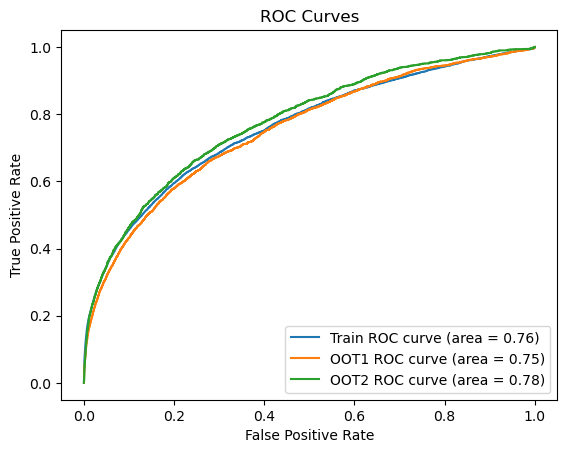

In [100]:
plt.plot(fpr_train, tpr_train, label='Train ROC curve (area = %0.2f)' % roc_auc_score(scores_train['y_true'], scores_train['y_pred']))
plt.plot(fpr_oot1, tpr_oot1, label='OOT1 ROC curve (area = %0.2f)' % roc_auc_score(scores_oot1['y_true'], scores_oot1['y_pred']))
plt.plot(fpr_oot2, tpr_oot2, label='OOT2 ROC curve (area = %0.2f)' % roc_auc_score(scores_oot2['y_true'], scores_oot2['y_pred']))
plt.legend()
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curves')
plt.show()

100%|██████████| 100/100 [00:07<00:00, 13.12it/s]


Mean bootstrap AUC: 0.7778
95% confidence interval: [0.7680, 0.7890]


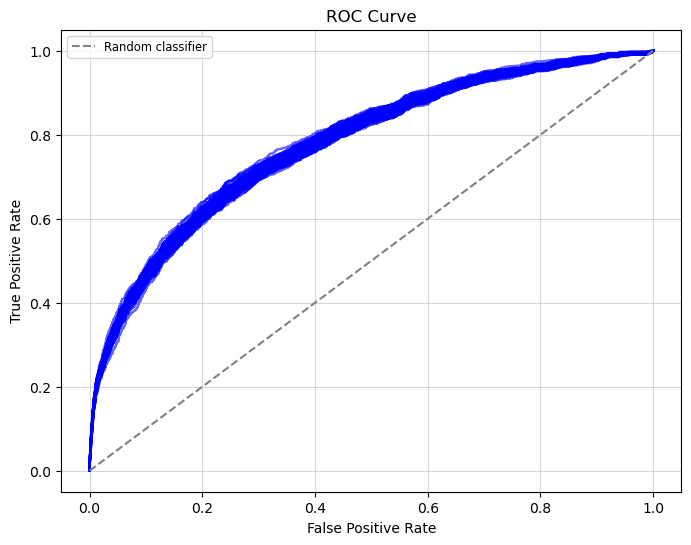

In [101]:
y = scores_oot2['y_true'].to_numpy()
score = scores_oot2['y_pred'].to_numpy()

n_bootstrap = 100
rng = np.random.default_rng(42)
aucs = []

plt.figure(figsize=(8, 6))

for i in tqdm(range(n_bootstrap)):
    indices = rng.choice(len(y), size=len(y), replace=True)
    y_bootstrap = y[indices]
    score_bootstrap = score[indices]

    roc_auc_bootstrap = roc_auc_score(y_bootstrap, score_bootstrap)
    aucs.append(roc_auc_bootstrap)
    fpr_bootstrap, tpr_bootstrap, _ = roc_curve(y_bootstrap, score_bootstrap)

    plt.plot(fpr_bootstrap, tpr_bootstrap, 'b', alpha=0.6)

auc_mean = np.mean(aucs)
auc_lower, auc_upper = np.percentile(aucs, [2.5, 97.5])
print(f"Mean bootstrap AUC: {auc_mean:.4f}")
print(f"95% confidence interval: [{auc_lower:.4f}, {auc_upper:.4f}]")
plt.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Random classifier")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend(fontsize="small")
plt.grid(alpha=0.5)
plt.show()